In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
PROJECT_ROOT = Path.cwd().parent
DATA_ROOT = PROJECT_ROOT / "data" / "raw"

for path in DATA_ROOT.rglob("*"):
    if path.is_dir():
        print(path.relative_to(DATA_ROOT))

A. Segmentation
A. Segmentation/2. All Segmentation Groundtruths
A. Segmentation/1. Original Images
A. Segmentation/2. All Segmentation Groundtruths/a. Training Set
A. Segmentation/2. All Segmentation Groundtruths/b. Testing Set
A. Segmentation/1. Original Images/a. Training Set
A. Segmentation/1. Original Images/b. Testing Set
A. Segmentation/2. All Segmentation Groundtruths/a. Training Set/5. Optic Disc
A. Segmentation/2. All Segmentation Groundtruths/a. Training Set/2. Haemorrhages
A. Segmentation/2. All Segmentation Groundtruths/a. Training Set/3. Hard Exudates
A. Segmentation/2. All Segmentation Groundtruths/a. Training Set/4. Soft Exudates
A. Segmentation/2. All Segmentation Groundtruths/a. Training Set/1. Microaneurysms
A. Segmentation/2. All Segmentation Groundtruths/b. Testing Set/5. Optic Disc
A. Segmentation/2. All Segmentation Groundtruths/b. Testing Set/2. Haemorrhages
A. Segmentation/2. All Segmentation Groundtruths/b. Testing Set/3. Hard Exudates
A. Segmentation/2. All S

In [3]:
from pathlib import Path

cwd = Path.cwd().resolve()

if (cwd / "data").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError("Could not find the project data directory.")

SEGMENTATION_ROOT = PROJECT_ROOT / "data" / "raw" / "A. Segmentation"

TRAIN_IMAGE_DIR = (
    SEGMENTATION_ROOT
    / "1. Original Images"
    / "a. Training Set"
)

TEST_IMAGE_DIR = (
    SEGMENTATION_ROOT
    / "1. Original Images"
    / "b. Testing Set"
)

TRAIN_MASK_ROOT = (
    SEGMENTATION_ROOT
    / "2. All Segmentation Groundtruths"
    / "a. Training Set"
)

print("Project root:", PROJECT_ROOT)
print("Training image folder exists:", TRAIN_IMAGE_DIR.exists())
print("Testing image folder exists:", TEST_IMAGE_DIR.exists())
print("Training mask folder exists:", TRAIN_MASK_ROOT.exists())

Project root: /Users/kkudenovaa/diabetic/diabetic-retinopathy-lesion-segmentation
Training image folder exists: True
Testing image folder exists: True
Training mask folder exists: True


In [4]:
train_images = sorted(TRAIN_IMAGE_DIR.glob("*.jpg"))
test_images = sorted(TEST_IMAGE_DIR.glob("*.jpg"))

print("Training images:", len(train_images))
print("Testing images:", len(test_images))
print("Example:", train_images[0])

Training images: 54
Testing images: 27
Example: /Users/kkudenovaa/diabetic/diabetic-retinopathy-lesion-segmentation/data/raw/A. Segmentation/1. Original Images/a. Training Set/IDRiD_01.jpg


In [5]:
def find_directory(root, keyword):
    matches = [
        path for path in root.iterdir()
        if path.is_dir() and keyword.lower() in path.name.lower()
    ]

    if len(matches) != 1:
        raise ValueError(
            f"Expected one directory containing '{keyword}', found: {matches}"
        )

    return matches[0]


MASK_DIRS = {
    "MA": find_directory(TRAIN_MASK_ROOT, "microaneurysm"),
    "HE": find_directory(TRAIN_MASK_ROOT, "haemorrhage"),
    "EX": find_directory(TRAIN_MASK_ROOT, "hard exudate"),
    "SE": find_directory(TRAIN_MASK_ROOT, "soft exudate"),
}

MASK_DIRS

{'MA': PosixPath('/Users/kkudenovaa/diabetic/diabetic-retinopathy-lesion-segmentation/data/raw/A. Segmentation/2. All Segmentation Groundtruths/a. Training Set/1. Microaneurysms'),
 'HE': PosixPath('/Users/kkudenovaa/diabetic/diabetic-retinopathy-lesion-segmentation/data/raw/A. Segmentation/2. All Segmentation Groundtruths/a. Training Set/2. Haemorrhages'),
 'EX': PosixPath('/Users/kkudenovaa/diabetic/diabetic-retinopathy-lesion-segmentation/data/raw/A. Segmentation/2. All Segmentation Groundtruths/a. Training Set/3. Hard Exudates'),
 'SE': PosixPath('/Users/kkudenovaa/diabetic/diabetic-retinopathy-lesion-segmentation/data/raw/A. Segmentation/2. All Segmentation Groundtruths/a. Training Set/4. Soft Exudates')}

In [6]:
LESIONS = {
    "MA": "microaneurysms",
    "HE": "hemorrhages",
    "EX": "hard_exudates",
    "SE": "soft_exudates",
}


def locate_mask(image_id, lesion_code):
    candidates = list(
        MASK_DIRS[lesion_code].glob(f"{image_id}*{lesion_code}*.tif")
    )

    if len(candidates) > 1:
        raise ValueError(
            f"Multiple {lesion_code} masks found for {image_id}: {candidates}"
        )

    return candidates[0] if candidates else None


records = []

for image_path in train_images:
    image_id = image_path.stem

    record = {
        "image_id": image_id,
        "image_path": str(image_path.relative_to(PROJECT_ROOT)),
    }

    for code, lesion_name in LESIONS.items():
        mask_path = locate_mask(image_id, code)

        record[f"{lesion_name}_mask"] = (
            str(mask_path.relative_to(PROJECT_ROOT))
            if mask_path is not None
            else ""
        )

        record[f"has_{lesion_name}"] = int(mask_path is not None)

    records.append(record)

metadata = pd.DataFrame(records)
metadata.head()

,image_id,image_path,microaneurysms_mask,has_microaneurysms,hemorrhages_mask,has_hemorrhages,hard_exudates_mask,has_hard_exudates,soft_exudates_mask,has_soft_exudates
0,IDRiD_01,data/raw/A. Segmentation/1. Original Images/a....,data/raw/A. Segmentation/2. All Segmentation G...,1,data/raw/A. Segmentation/2. All Segmentation G...,1,data/raw/A. Segmentation/2. All Segmentation G...,1,,0
1,IDRiD_02,data/raw/A. Segmentation/1. Original Images/a....,data/raw/A. Segmentation/2. All Segmentation G...,1,data/raw/A. Segmentation/2. All Segmentation G...,1,data/raw/A. Segmentation/2. All Segmentation G...,1,,0
2,IDRiD_03,data/raw/A. Segmentation/1. Original Images/a....,data/raw/A. Segmentation/2. All Segmentation G...,1,data/raw/A. Segmentation/2. All Segmentation G...,1,data/raw/A. Segmentation/2. All Segmentation G...,1,data/raw/A. Segmentation/2. All Segmentation G...,1
3,IDRiD_04,data/raw/A. Segmentation/1. Original Images/a....,data/raw/A. Segmentation/2. All Segmentation G...,1,data/raw/A. Segmentation/2. All Segmentation G...,1,data/raw/A. Segmentation/2. All Segmentation G...,1,,0
4,IDRiD_05,data/raw/A. Segmentation/1. Original Images/a....,data/raw/A. Segmentation/2. All Segmentation G...,1,data/raw/A. Segmentation/2. All Segmentation G...,1,data/raw/A. Segmentation/2. All Segmentation G...,1,,0


In [7]:
assert len(metadata) == 54
assert metadata["image_id"].is_unique

metadata.shape

(54, 10)

In [8]:
for code, lesion_name in LESIONS.items():
    presence = []

    for _, row in metadata.iterrows():
        mask_value = row[f"{lesion_name}_mask"]

        if not mask_value:
            presence.append(0)
            continue

        mask = cv2.imread(
            str(PROJECT_ROOT / mask_value),
            cv2.IMREAD_GRAYSCALE,
        )

        if mask is None:
            raise ValueError(f"Could not read mask: {mask_value}")

        presence.append(int(np.any(mask > 0)))

    metadata[f"has_{lesion_name}"] = presence

In [9]:
presence_columns = [
    f"has_{lesion_name}"
    for lesion_name in LESIONS.values()
]

lesion_counts = metadata[presence_columns].sum()
lesion_counts.index = [
    name.replace("has_", "").replace("_", " ").title()
    for name in lesion_counts.index
]

display(lesion_counts)

Microaneurysms    54
Hemorrhages       53
Hard Exudates     54
Soft Exudates     26
dtype: int64

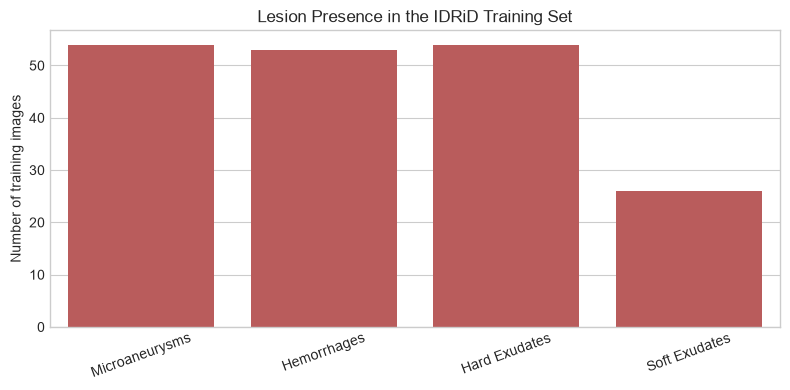

In [13]:
figure_path = PROJECT_ROOT / "assets" / "lesion_distribution.png"
plt.figure(figsize=(8, 4))

sns.barplot(
    x=lesion_counts.index,
    y=lesion_counts.values,
    color="#C94C4C",
)

plt.ylabel("Number of training images")
plt.xlabel("")
plt.title("Lesion Presence in the IDRiD Training Set")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

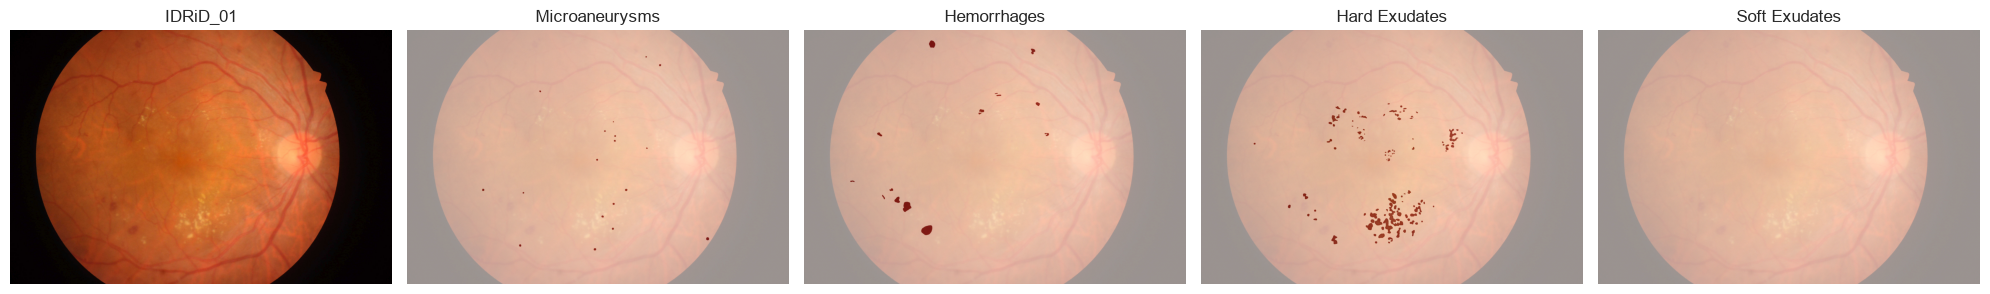

In [14]:
def read_mask(mask_path, image_shape):
    if not mask_path:
        return np.zeros(image_shape[:2], dtype=np.uint8)

    mask = cv2.imread(
        str(PROJECT_ROOT / mask_path),
        cv2.IMREAD_GRAYSCALE,
    )

    if mask is None:
        raise ValueError(f"Could not load {mask_path}")

    return (mask > 0).astype(np.uint8)


def show_sample(row):
    image = cv2.imread(str(PROJECT_ROOT / row["image_path"]))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    fig, axes = plt.subplots(1, 5, figsize=(20, 5))

    axes[0].imshow(image)
    axes[0].set_title(row["image_id"])

    for axis, lesion_name in zip(axes[1:], LESIONS.values()):
        mask = read_mask(
            row[f"{lesion_name}_mask"],
            image.shape,
        )

        axis.imshow(image)
        axis.imshow(mask, cmap="Reds", alpha=0.6)
        axis.set_title(lesion_name.replace("_", " ").title())

    for axis in axes:
        axis.axis("off")

    plt.tight_layout()
    plt.show()


show_sample(metadata.iloc[0])

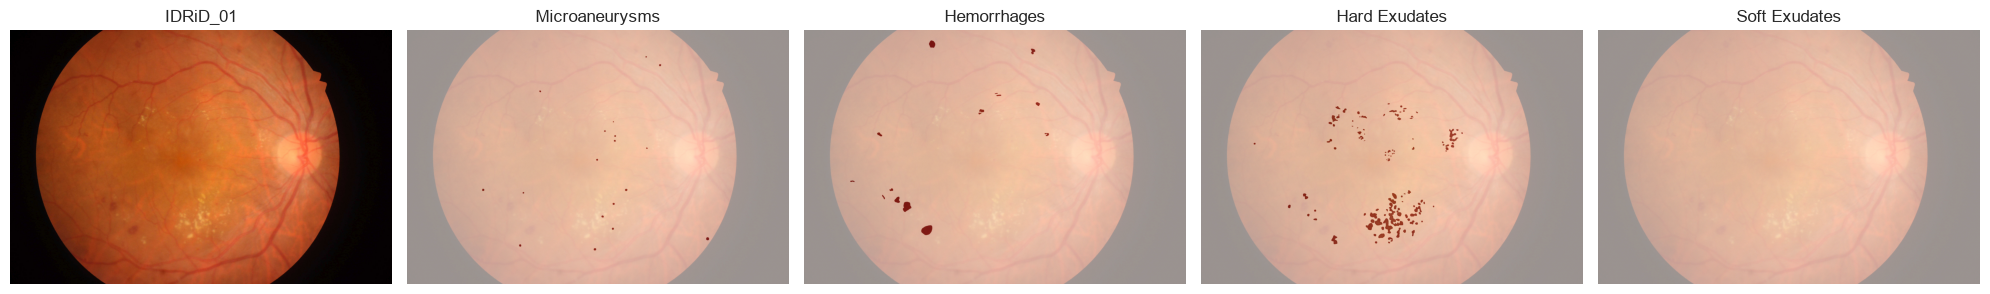

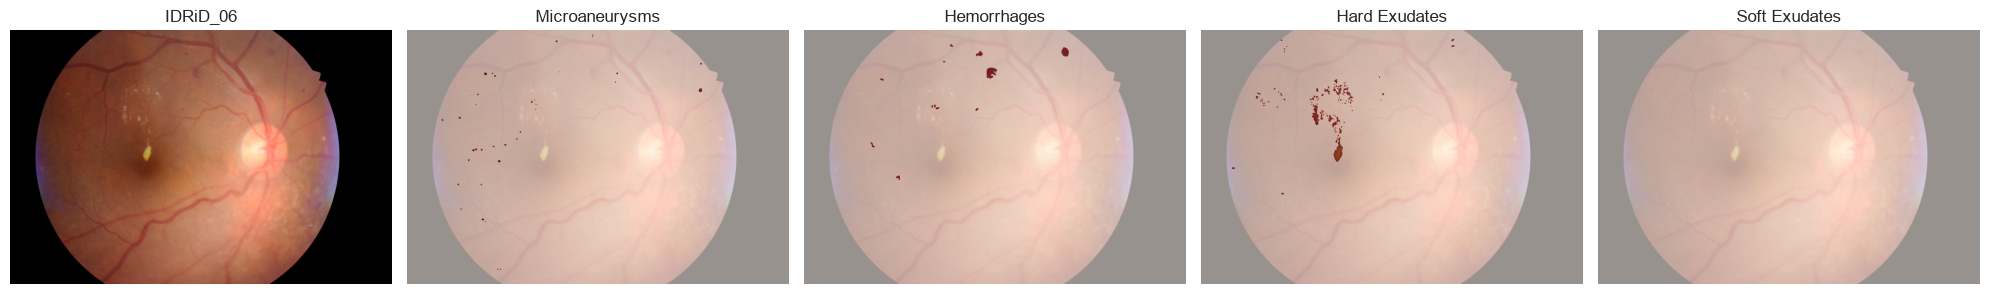

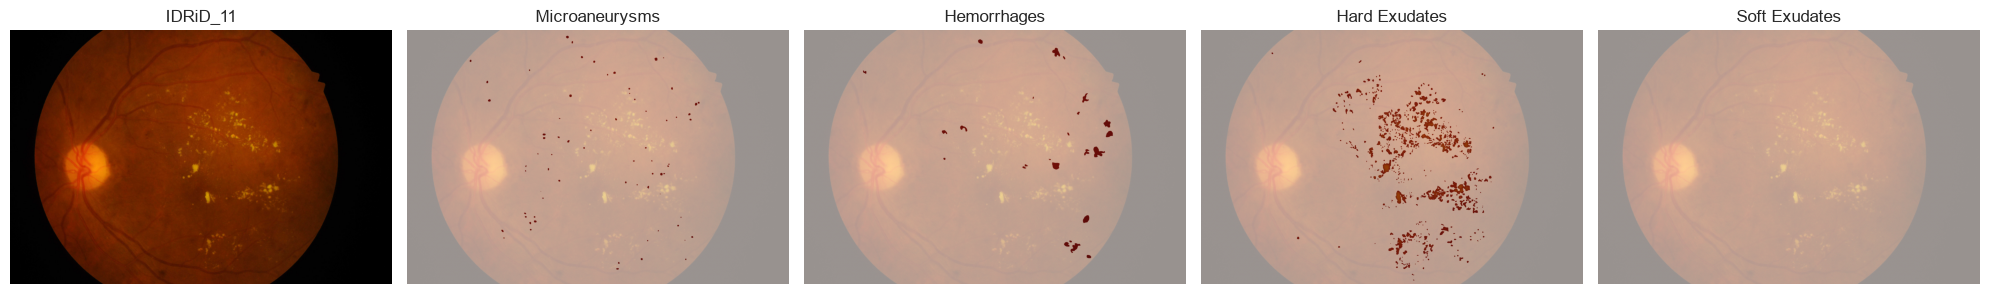

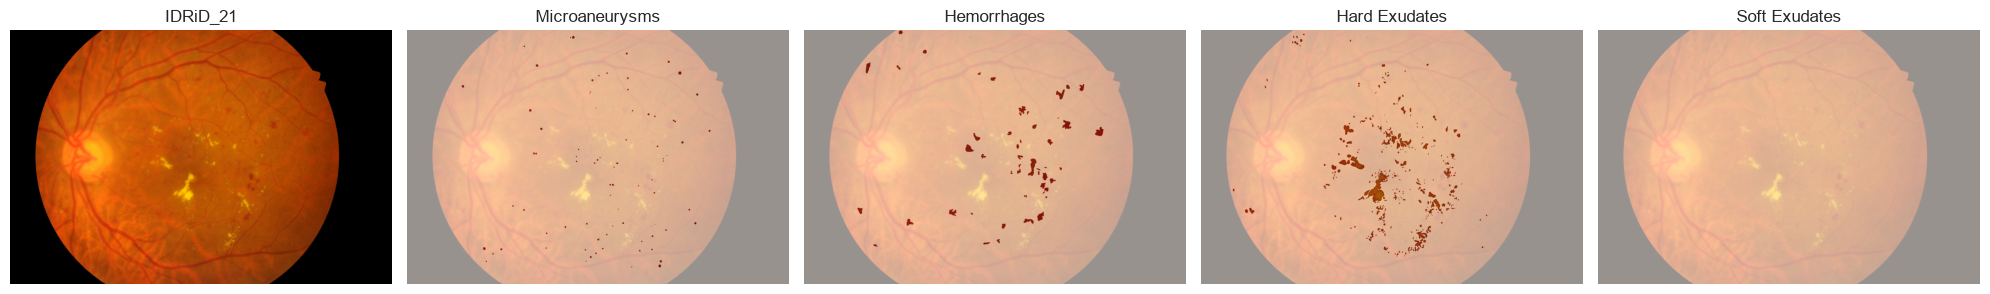

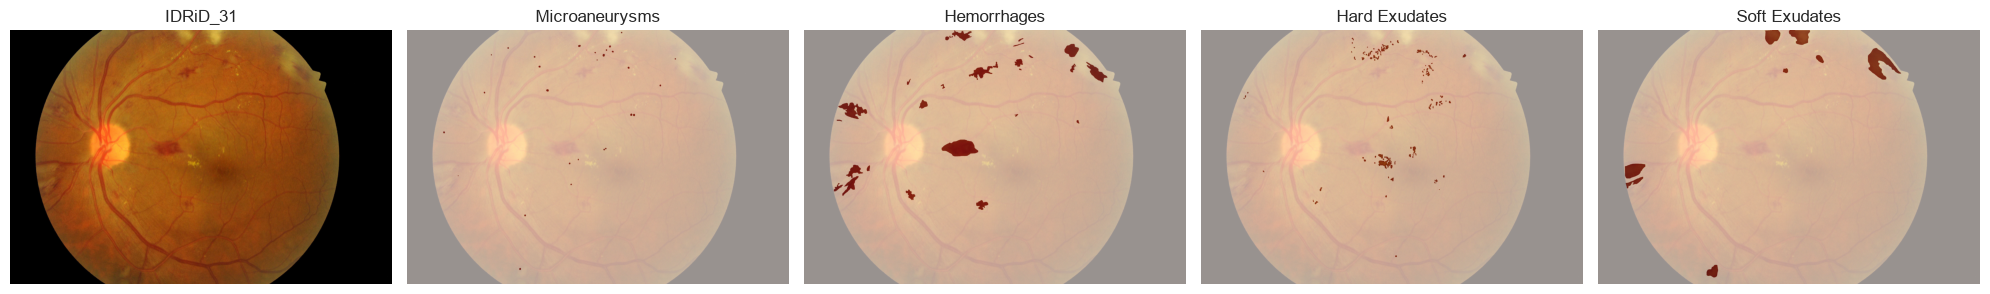

In [15]:
for index in [0, 5, 10, 20, 30]:
    show_sample(metadata.iloc[index])

In [16]:
statistics = []

for _, row in metadata.iterrows():
    image = cv2.imread(str(PROJECT_ROOT / row["image_path"]))

    record = {
        "image_id": row["image_id"],
        "height": image.shape[0],
        "width": image.shape[1],
    }

    for lesion_name in LESIONS.values():
        mask = read_mask(
            row[f"{lesion_name}_mask"],
            image.shape,
        )

        record[f"{lesion_name}_pixels"] = int(mask.sum())
        record[f"{lesion_name}_fraction"] = float(mask.mean())

    statistics.append(record)

statistics = pd.DataFrame(statistics)
statistics.describe().T

,count,mean,std,min,25%,50%,75%,max
height,54.0,2848.000000,0.000000,2848.000000,2848.000000,2848.000000,2848.000000,2.848000e+03
width,54.0,4288.000000,0.000000,4288.000000,4288.000000,4288.000000,4288.000000,4.288000e+03
microaneurysms_pixels,54.0,13054.870370,10506.044544,804.000000,4599.500000,9651.500000,21516.000000,3.806600e+04
microaneurysms_fraction,54.0,0.001069,0.000860,0.000066,0.000377,0.000790,0.001762,3.117041e-03
hemorrhages_pixels,54.0,120379.351852,256093.018623,0.000000,25841.000000,57568.000000,103972.250000,1.821322e+06
hemorrhages_fraction,54.0,0.009857,0.020970,0.000000,0.002116,0.004714,0.008514,1.491393e-01
hard_exudates_pixels,54.0,98509.703704,147134.482307,2343.000000,13116.250000,40639.500000,131714.250000,8.052500e+05
hard_exudates_fraction,54.0,0.008066,0.012048,0.000192,0.001074,0.003328,0.010785,6.593803e-02
soft_exudates_pixels,54.0,23130.388889,35160.735279,0.000000,0.000000,0.000000,39517.500000,1.580770e+05
soft_exudates_fraction,54.0,0.001894,0.002879,0.000000,0.000000,0.000000,0.003236,1.294416e-02


In [17]:
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

X = metadata[["image_id"]].values
y = metadata[presence_columns].values

splitter = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42,
)

train_indices, validation_indices = next(splitter.split(X, y))

metadata["split"] = ""

metadata.loc[train_indices, "split"] = "train"
metadata.loc[validation_indices, "split"] = "validation"

metadata["split"].value_counts()

split
train         43
validation    11
Name: count, dtype: int64

In [18]:
split_distribution = (
    metadata
    .groupby("split")[presence_columns]
    .sum()
    .T
)

split_distribution.index = [
    name.replace("has_", "").replace("_", " ").title()
    for name in split_distribution.index
]

split_distribution

split,train,validation
Microaneurysms,43,11
Hemorrhages,42,11
Hard Exudates,43,11
Soft Exudates,21,5


In [19]:
train_ids = set(
    metadata.loc[metadata["split"] == "train", "image_id"]
)

validation_ids = set(
    metadata.loc[metadata["split"] == "validation", "image_id"]
)

assert train_ids.isdisjoint(validation_ids)
assert len(train_ids) == 43
assert len(validation_ids) == 11
assert len(train_ids | validation_ids) == 54

print("Split verified: no overlap or missing images.")

Split verified: no overlap or missing images.


In [20]:
output_directory = PROJECT_ROOT / "data" / "splits"
output_directory.mkdir(parents=True, exist_ok=True)

metadata.to_csv(
    output_directory / "idrid_training_metadata.csv",
    index=False,
)

metadata.loc[
    metadata["split"] == "train", ["image_id"]
].to_csv(
    output_directory / "train_ids.csv",
    index=False,
)

metadata.loc[
    metadata["split"] == "validation", ["image_id"]
].to_csv(
    output_directory / "validation_ids.csv",
    index=False,
)

print("Split files saved to:", output_directory)

Split files saved to: /Users/kkudenovaa/diabetic/diabetic-retinopathy-lesion-segmentation/data/splits
